# Dublin Bikes — Exploratory Analysis

This notebook explores usage patterns in the Dublin Bikes network using data
collected from the public **GBFS** (General Bikeshare Feed Specification) feed.

**Pipeline so far:**
1. `scripts/collect_data.py` polls the live API and appends a snapshot of every
   station's bike/dock availability to `data/raw/station_status_*.csv`.
2. `scripts/clean_data.py` merges those snapshots with static station info
   (name, location, capacity) and writes one tidy table to
   `data/processed/station_status_clean.csv`.

This notebook picks up from that clean table. Why a notebook for this part,
rather than another script? Analysis is *exploratory* — we don't know in
advance which question will turn out interesting, so we want fast
iteration and inline plots, not "run the whole file to see one number."
Once an analysis stabilizes into something we want every time (like the
occupancy calculation), it graduates into a script — that's exactly what
happened with `clean_data.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# The same fixed-order categorical palette used in the Streamlit dashboard,
# so a station (or any category) is colored consistently across the whole
# project instead of getting reshuffled colors depending on which chart
# library happened to draw it.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = "#2a78d6"

DATA_PATH = "../data/processed/station_status_clean.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["query_time"])
df["date"] = pd.to_datetime(df["date"])
df.head()

,query_time,date,hour,day_of_week,station_id,name,lat,lon,capacity,num_bikes_available,num_docks_available,occupancy_ratio,is_renting,is_returning
0,2026-08-04 21:10:01+00:00,2026-08-04,21,Tuesday,1,CLARENDON ROW,53.340927,-6.262501,31,0,31,0.0,True,True
1,2026-08-04 21:11:06+00:00,2026-08-04,21,Tuesday,1,CLARENDON ROW,53.340927,-6.262501,31,0,31,0.0,True,True
2,2026-08-04 21:12:36+00:00,2026-08-04,21,Tuesday,1,CLARENDON ROW,53.340927,-6.262501,31,0,31,0.0,True,True
3,2026-08-04 21:14:06+00:00,2026-08-04,21,Tuesday,1,CLARENDON ROW,53.340927,-6.262501,31,0,31,0.0,True,True
4,2026-08-04 21:15:37+00:00,2026-08-04,21,Tuesday,1,CLARENDON ROW,53.340927,-6.262501,31,0,31,0.0,True,True


## 1. Get oriented

Before asking "what's the usage pattern", check basic shape and quality: how
many stations, how many snapshots, any missing values, does anything look
broken (e.g. occupancy below 0 or above 1)?

In [2]:
print(f"Rows: {len(df):,}")
print(f"Stations: {df['station_id'].nunique()}")
print(f"Snapshot times: {df['query_time'].nunique()}")
print(f"Date range: {df['query_time'].min()} to {df['query_time'].max()}")
print()
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

Rows: 87,894
Stations: 114
Snapshot times: 771
Date range: 2026-08-04 21:10:01+00:00 to 2026-08-11 00:34:02+00:00

Missing values per column:
Series([], dtype: int64)


In [3]:
df["occupancy_ratio"].describe()

count    87894.000000
mean         0.391670
std          0.327061
min          0.000000
25%          0.100000
50%          0.318182
75%          0.666667
max          1.000000
Name: occupancy_ratio, dtype: float64

`occupancy_ratio` is bikes-available ÷ capacity, so it should always sit
between 0 (empty) and 1 (full) — `clean_data.py` already clips it there, so
this is really just double-checking that step worked, not re-deriving it.

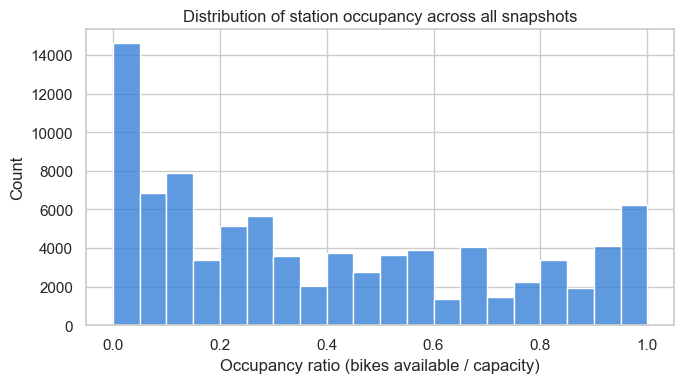

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["occupancy_ratio"], bins=20, color=BLUE, ax=ax)
ax.set_xlabel("Occupancy ratio (bikes available / capacity)")
ax.set_title("Distribution of station occupancy across all snapshots")
plt.tight_layout()
plt.show()

## 2. Which stations run busiest?

We read "demand" off *low* average occupancy: a station that's usually
near-empty is one where bikes get taken faster than they're returned (think
a station at the bottom of a hill on the commute into town). A station
that's usually near-full is a popular *drop-off* point. Both are useful to
know — for a bike-share operator, both are candidates for manual
rebalancing (trucks moving bikes between stations).

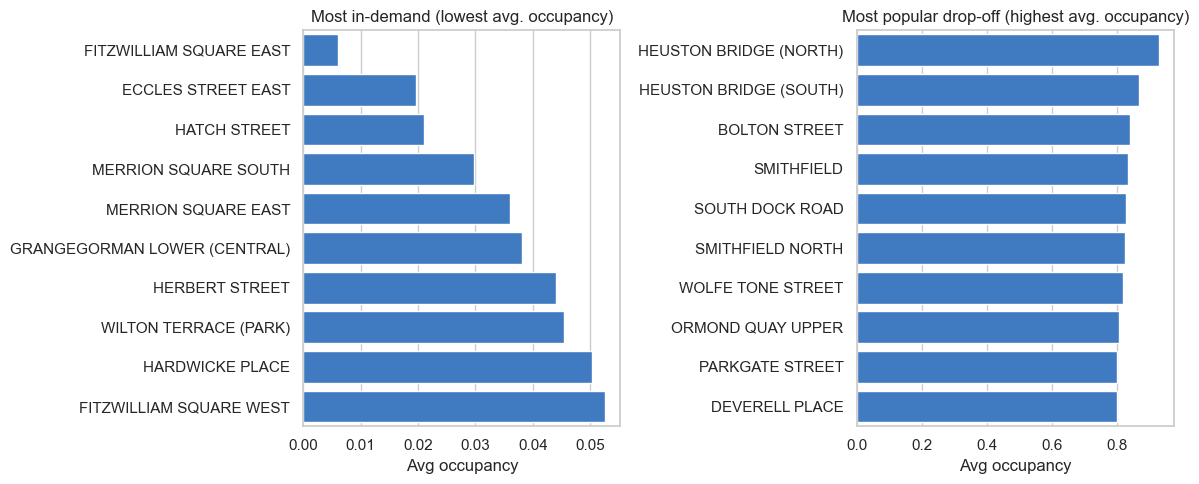

In [5]:
station_avg = (
    df.groupby(["station_id", "name"], as_index=False)["occupancy_ratio"]
    .mean()
    .sort_values("occupancy_ratio")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

emptiest = station_avg.head(10)
sns.barplot(data=emptiest, x="occupancy_ratio", y="name", color=BLUE, ax=axes[0])
axes[0].set_title("Most in-demand (lowest avg. occupancy)")
axes[0].set_xlabel("Avg occupancy")
axes[0].set_ylabel("")

fullest = station_avg.tail(10).sort_values("occupancy_ratio", ascending=False)
sns.barplot(data=fullest, x="occupancy_ratio", y="name", color=BLUE, ax=axes[1])
axes[1].set_title("Most popular drop-off (highest avg. occupancy)")
axes[1].set_xlabel("Avg occupancy")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 3. Does station size relate to how full it runs?

A quick sanity-check question: do bigger stations (more docks) run fuller or
emptier on average, or is capacity unrelated to occupancy? If there's no
real relationship, we'd expect a scatterplot to look like a random cloud
and a correlation coefficient near 0.

Correlation between capacity and avg occupancy: -0.36


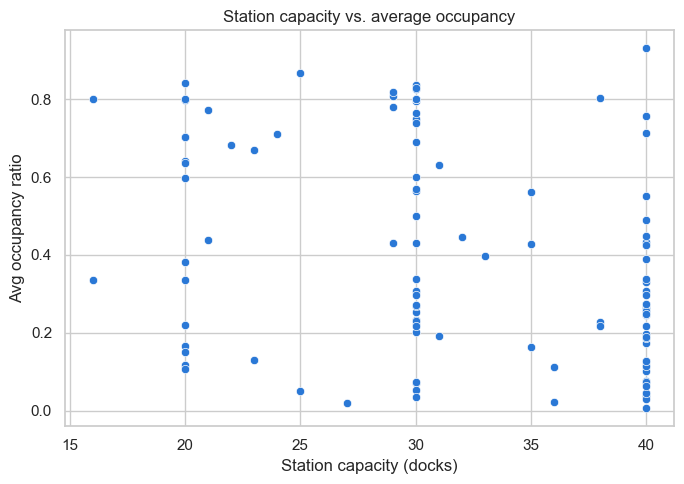

In [6]:
station_capacity = df.groupby(["station_id", "name"], as_index=False).agg(
    avg_occupancy=("occupancy_ratio", "mean"),
    capacity=("capacity", "first"),
)

corr = station_capacity["capacity"].corr(station_capacity["avg_occupancy"])
print(f"Correlation between capacity and avg occupancy: {corr:.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=station_capacity, x="capacity", y="avg_occupancy", color=BLUE, ax=ax)
ax.set_xlabel("Station capacity (docks)")
ax.set_ylabel("Avg occupancy ratio")
ax.set_title("Station capacity vs. average occupancy")
plt.tight_layout()
plt.show()

## 4. How does occupancy change over time?

This is the question the whole project is really built around, and it's
also the one most limited by *how long the collector has been running* —
GBFS only ever gives you the current instant, so "yesterday's rush hour"
only exists if something was polling and saving it at the time.

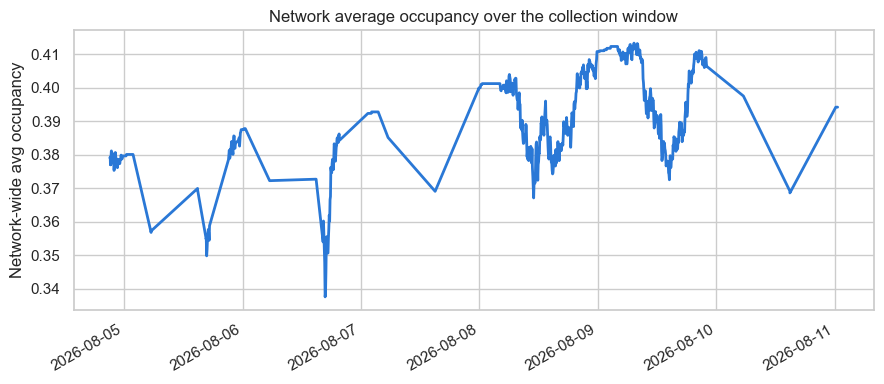

Data spans 8 day(s) so far.


In [7]:
network_avg = df.groupby("query_time", as_index=False)["occupancy_ratio"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(network_avg["query_time"], network_avg["occupancy_ratio"], color=BLUE, linewidth=2)
ax.set_ylabel("Network-wide avg occupancy")
ax.set_xlabel("")
ax.set_title("Network average occupancy over the collection window")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

n_days = df["date"].nunique()
print(f"Data spans {n_days} day(s) so far.")
if n_days < 2:
    print(
        "Only a short collection window is available right now, so hour-of-day "
        "and day-of-week patterns below won't be meaningful yet. Run "
        "`python scripts/collect_data.py --loop --interval 300` for a few days "
        "(e.g. as a cron job or Windows scheduled task) to see real commuter "
        "rush-hour patterns emerge."
    )

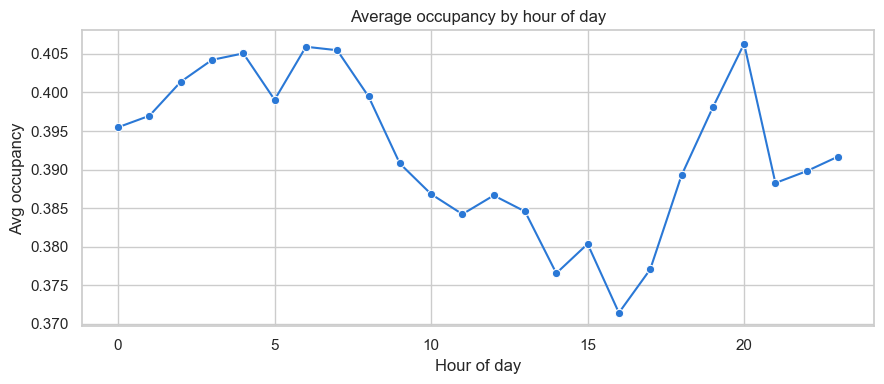

In [8]:
df["hour"] = df["query_time"].dt.hour
hourly = df.groupby("hour", as_index=False)["occupancy_ratio"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=hourly, x="hour", y="occupancy_ratio", color=BLUE, marker="o", ax=ax)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Avg occupancy")
ax.set_title("Average occupancy by hour of day")
plt.tight_layout()
plt.show()

## 5. Takeaways & next steps

- The busiest/quietest station lists above are exactly the kind of thing a
  bike-share operator uses to plan manual rebalancing routes.
- Station capacity alone doesn't strongly predict how full a station runs —
  location (is it downhill from a busy commuter route? near a train
  station?) plausibly matters more than size.
- The hour-of-day view is where this analysis gets genuinely interesting,
  but it needs `collect_data.py` to have been running for at least a few
  full days to smooth out noise and reveal real commuter rush-hour dips
  and peaks.

Natural next steps if you wanted to take this further:
- Let the collector run for 1-2 weeks, then re-run this notebook — you
  should start to see a clear weekday commute signature (empty in the
  morning at residential-area stations, full at business-district ones).
- Bring in a weather API and check whether rain suppresses ridership.
- Turn the hour-of-day averages into a simple next-hour occupancy
  predictor for a given station.
- The `dashboard/app.py` Streamlit app turns several of these plots into an
  interactive, filterable dashboard — run `streamlit run dashboard/app.py`
  from the project root.